# Managing overlap with weights and sequential sampling

This native Julia companion uses the same public minute records, fifteen-minute resampling, inclusive event spans, and public weighting formulas. Sequential sampling retains the original conditional uniqueness rule and 80 paired repetitions. Its local Xoshiro generator uses seed 20260926; Julia and NumPy streams differ, so every selection and primitive uniform draw is saved for independent replay. Plots use the requested dark theme, with results saved under `outputs/julia`.

The released rule increases a multiplier from an old-data level toward one as cumulative event weight moves forward:

$$
Q_i=\sum_{j=1}^{i}q_j,\qquad
d_i(c)=c+(1-c)\frac{Q_i}{Q_n},\qquad 0\leq c\leq1.
$$

Here, $q_j\geq0$ is the input weight of ordered event $j$; $Q_i$ is cumulative weight through event $i$; $Q_n$ is total weight. $c\in[0,1]$ is the chosen old-data level; $d_i(c)$ is the multiplier for event $i$; $d_n(c)=1.$

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("07_overlapping_information_weights");
using CSV, Printf
using RiskLabAI.Data: daily_volatility_with_log_returns,symmetric_cusum_filter,cusum_filter_events_dynamic_threshold,vertical_barrier,triple_barrier,meta_labeling,calculate_t_value_linear_regression,find_trend_using_trend_scanning
raw = load_binance()
data_path = dataset_path("binance_btcusdt")
@assert isfile(data_path)
close_index,close_prices = raw.time,raw.close
log_price = log.(close_prices)
price_positions = Dict(time=>position for (position,time) in enumerate(close_index))
violet = "#C084FC"

function count_histogram!(figure,values,bins;color,label=false,alpha=.75)
    edges = collect(range(minimum(values),maximum(values);length=bins+1))
    counts = [count(value->edges[index]<=value && (value<edges[index+1] || index==bins && value==edges[end]),values) for index in 1:bins]
    bar!(figure,(edges[1:end-1].+edges[2:end])./2,counts;bar_width=diff(edges),color,fillalpha=alpha,linecolor=color,label)
    ylims!(figure,0.,1.1max(maximum(counts),last(ylims(figure))))
    return DataFrame(left=edges[1:end-1],right=edges[2:end],count=counts)
end

function box_summary!(figure,groups,colors)
    for (index,values) in enumerate(groups)
        lower,middle,upper = quantile(values,[.25,.5,.75])
        spread = upper-lower
        bottom = minimum(values[values.>=lower-1.5spread])
        top = maximum(values[values.<=upper+1.5spread])
        plot!(figure,Shape([index-.25,index+.25,index+.25,index-.25],[lower,lower,upper,upper]);color=colors[index],fillalpha=.65,linecolor=palette.text,label=false)
        plot!(figure,[index-.25,index+.25],[middle,middle];color=palette.text,label=false)
        plot!(figure,[index,index],[bottom,lower];color=palette.text,label=false)
        plot!(figure,[index,index],[upper,top];color=palette.text,label=false)
        for height in (bottom,top)
            plot!(figure,[index-.12,index+.12],[height,height];color=palette.text,label=false)
        end
    end
    return figure
end
using RiskLabAI.Data: calculate_average_uniqueness,calculate_time_decay,expand_label_for_meta_labeling,sample_weight_absolute_return_meta_labeling,sequential_bootstrap
minute_close = copy(close_prices)
resampled = combine(groupby(DataFrame(time=floor.(raw.time,Minute(15)),price=raw.close),:time;sort=true),:price=>last=>:close)
close_index,close_prices = resampled.time,resampled.close
log_price = log.(close_prices)
price_positions = Dict(time=>position for (position,time) in enumerate(close_index))
span = 100
volatility = daily_volatility_with_log_returns(close_index,close_prices;span)
volatility_lookup = Dict(zip(volatility.index,volatility.volatility))

function dynamic_threshold_events(multiplier)
    selected = findall(isfinite,volatility.volatility)
    positions = [price_positions[volatility.index[index]] for index in selected]
    aligned = vcat(first(positions)-1,positions)
    return cusum_filter_events_dynamic_threshold(close_index[aligned],log_price[aligned],vcat(NaN,multiplier.*volatility.volatility[selected]))
end
event_times = dynamic_threshold_events(1.)
vertical_times = vertical_barrier(close_index,event_times,1)
ending_lookup = Dict(zip(vertical_times.event,vertical_times.barrier))
event_times = [time for time in event_times if haskey(ending_lookup,time) && isfinite(get(volatility_lookup,time,NaN))]
event_ends = [ending_lookup[time] for time in event_times]
start_positions,end_positions = [price_positions[time] for time in event_times],[price_positions[time] for time in event_ends]
indicator_matrix = Int[time>=start && time<=ending for time in close_index,(start,ending) in zip(event_times,event_ends)]
event_duration = vec(sum(indicator_matrix;dims=1))
matrix_concurrency = vec(sum(indicator_matrix;dims=2))
active_concurrency = matrix_concurrency[matrix_concurrency.>0]
library_concurrency = expand_label_for_meta_labeling(close_index,event_times,event_ends,event_times);


## Decay Along Cumulative Information

Row,Old-data level,Oldest observed factor,Newest factor,Effective sample size,Largest ten weights' share
,Float64,Float64,Float64,Float64,Float64
1,1.0,1.0,1.0,104.505,0.170115
2,0.5,0.503807,1.0,101.544,0.183161
3,0.0,0.00761458,1.0,79.4192,0.23663


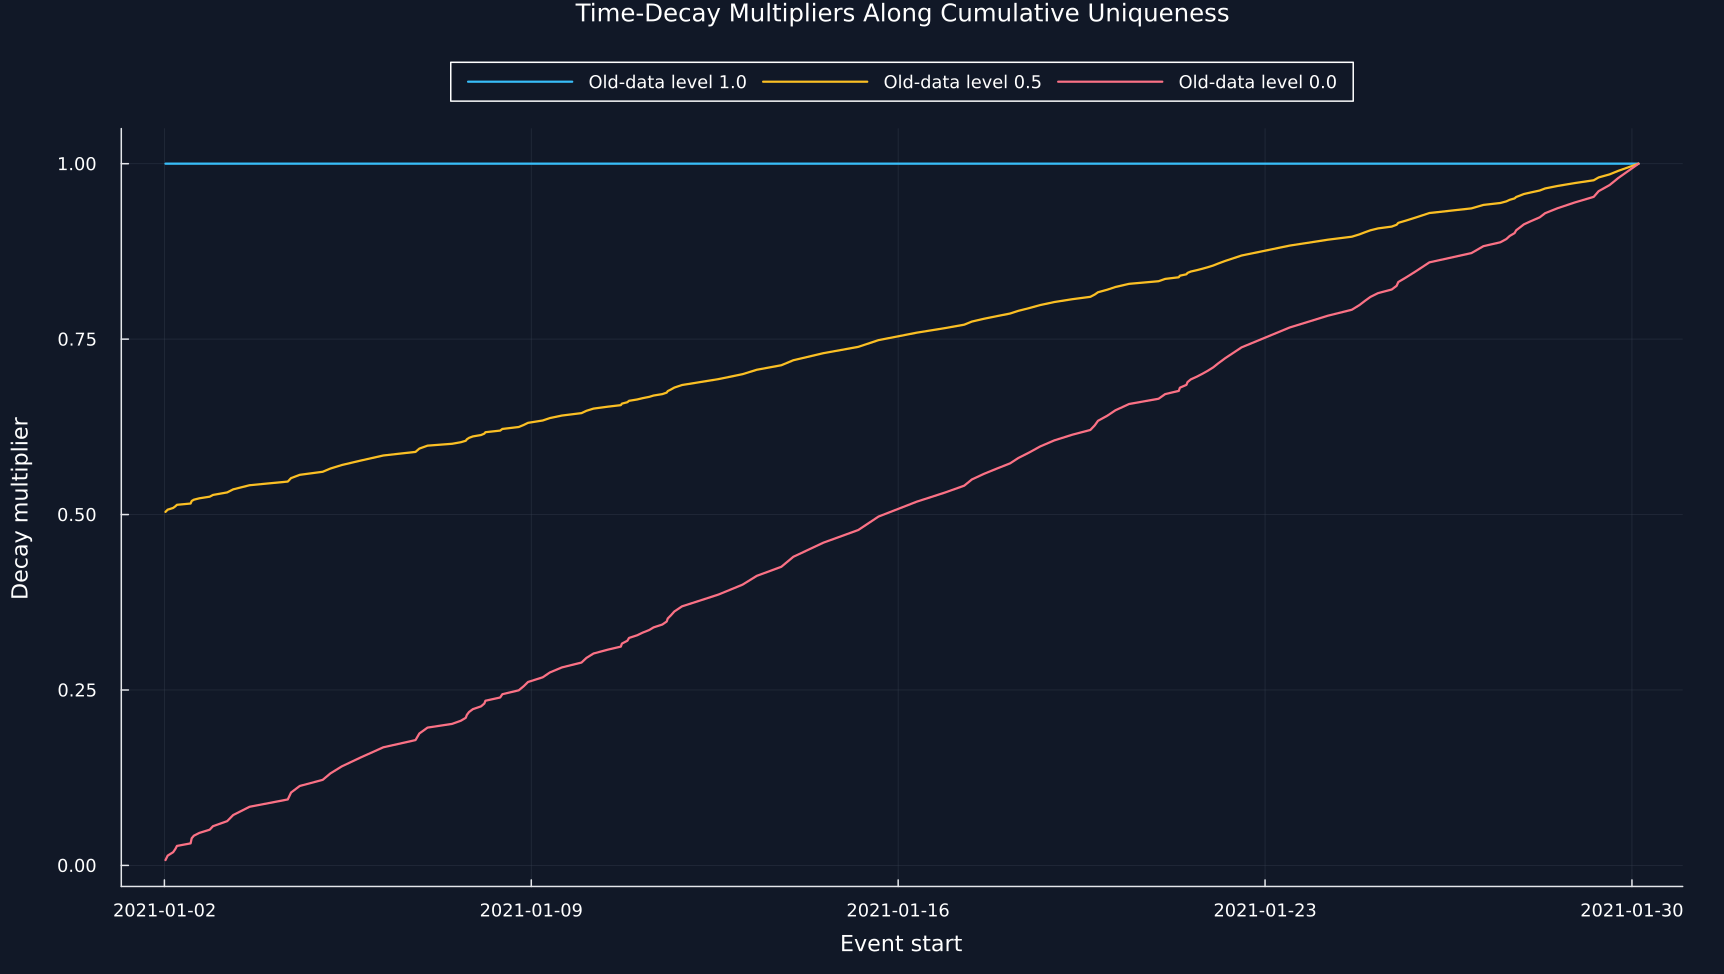

In [2]:
average_uniqueness = calculate_average_uniqueness(indicator_matrix)
attribution_weights = sample_weight_absolute_return_meta_labeling(event_times,event_ends,close_index,close_prices,event_times)
effective_sample_size(weight) = sum(weight)^2/sum(abs2,weight)
decay_levels = [1.,.5,0.]
decay_factors = Dict(level=>calculate_time_decay(average_uniqueness;clf_last_weight=level) for level in decay_levels)
final_weights = Dict(level=>attribution_weights.*decay_factors[level] for level in decay_levels)
time_decay_summary = DataFrame("Old-data level"=>decay_levels,"Oldest observed factor"=>[first(decay_factors[level]) for level in decay_levels],"Newest factor"=>[last(decay_factors[level]) for level in decay_levels],"Effective sample size"=>[effective_sample_size(final_weights[level]) for level in decay_levels],"Largest ten weights' share"=>[sum(sort(final_weights[level];rev=true)[1:10])/sum(final_weights[level]) for level in decay_levels])
save_table(time_decay_summary,paths,"time_decay_summary";caption="Time-decay factors and effective sample sizes for the public event sample.",label="tab:chapter6-time-decay")
figure = plot(;title="Time-Decay Multipliers Along Cumulative Uniqueness",xlabel="Event start",ylabel="Decay multiplier",ylims=(-.03,1.05),legend=:outertop,legend_column=3,size=(1150,650))
decay_rows = NamedTuple[]
for (level,color) in zip(decay_levels,[palette.cyan,palette.amber,palette.rose])
    plot!(figure,event_times,decay_factors[level];color,linewidth=1.5,label="Old-data level "*string(level))
    append!(decay_rows,[(;level,event=index,time=event_times[index],uniqueness=average_uniqueness[index],attribution=attribution_weights[index],factor=decay_factors[level][index],weight=final_weights[level][index]) for index in eachindex(event_times)])
end
save_data(DataFrame(decay_rows),paths,"decay_weight_records")
save_figure(figure,paths,"time_decay_factors")


## Sequential Sampling

Before draw $k,$ every candidate is scored by the uniqueness it would add, and its score becomes its draw probability:

$$
\overline u_j^{(k)}=\frac{1}{L_j}\sum_t\frac{I_{tj}}{c_t^{(k-1)}+I_{tj}},\qquad
p_j^{(k)}=\frac{\overline u_j^{(k)}}{\sum_{\ell=1}^{n}\overline u_\ell^{(k)}}.
$$

Here, $k$ is the draw number; $j$ and $\ell$ label candidate events; $L_j$ is candidate $j$'s length. $c_t^{(k-1)}$ is concurrency from earlier draws; $I_{tj}$ is candidate activity; $\overline u_j^{(k)}$ is added uniqueness; $p_j^{(k)}$ is draw probability.

Row,Method,Mean uniqueness,10th percentile,Middle value,90th percentile,Paired wins
,String,Float64,Float64,Float64,Float64,Int64
1,Ordinary sampling with replacement,0.203253,0.195799,0.204015,0.210844,3
2,Sequential uniqueness sampling,0.213981,0.211286,0.214518,0.21634,77


Row,Group,Ordinary share,Sequential share,Sequential minus ordinary
,String,Float64,Float64,Float64
1,Lowest uniqueness,0.259586,0.195489,-0.0640977
2,Lower middle,0.244643,0.214004,-0.0306391
3,Upper middle,0.249436,0.263252,0.0138158
4,Highest uniqueness,0.246335,0.327256,0.0809211


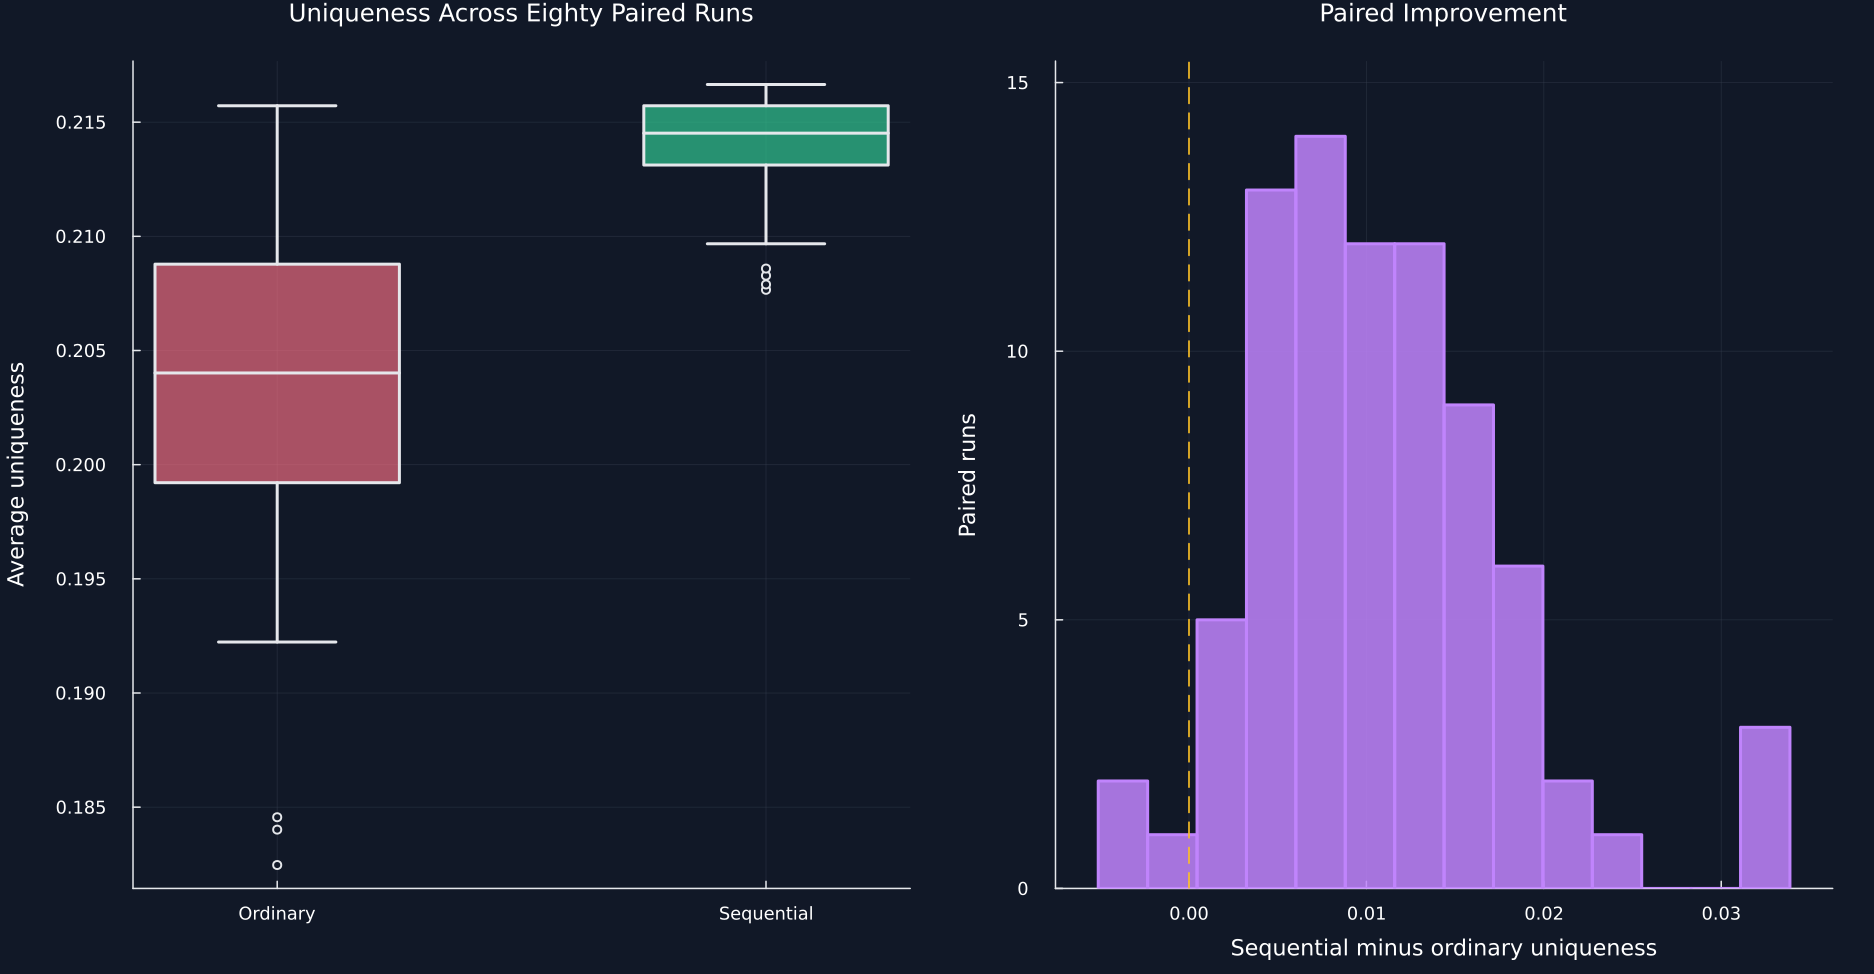

In [3]:
sample_average_uniqueness(draw) = mean(calculate_average_uniqueness(indicator_matrix[:,draw]))

function sequential_sample(generator,sample_length)
    concurrency = zeros(Int,size(indicator_matrix,1))
    draws,uniforms = Int[],Float64[]
    for position in 1:sample_length
        scores = [mean(1 ./ (concurrency[left:right].+1)) for (left,right) in zip(start_positions,end_positions)]
        uniform = rand(generator)
        chosen = min(searchsortedfirst(cumsum(scores./sum(scores)),uniform),length(event_times))
        push!(draws,chosen)
        push!(uniforms,uniform)
        concurrency[start_positions[chosen]:end_positions[chosen]] .+= 1
    end
    return draws,uniforms
end
generator = Xoshiro(20260926)
repetitions,event_count = 80,length(event_times)
ordinary_draws,sequential_draws = zeros(Int,repetitions,event_count),zeros(Int,repetitions,event_count)
ordinary_uniqueness,sequential_uniqueness = zeros(repetitions),zeros(repetitions)
draw_rows = NamedTuple[]
for repetition in 1:repetitions
    ordinary = rand(generator,1:event_count,event_count)
    sequential,uniforms = sequential_sample(generator,event_count)
    ordinary_draws[repetition,:],sequential_draws[repetition,:] = ordinary,sequential
    ordinary_uniqueness[repetition] = sample_average_uniqueness(ordinary)
    sequential_uniqueness[repetition] = sample_average_uniqueness(sequential)
    append!(draw_rows,[(;repetition,position,ordinary=ordinary[position],sequential=sequential[position],uniform=uniforms[position]) for position in 1:event_count])
end
paired_difference = sequential_uniqueness.-ordinary_uniqueness
sampling_summary = DataFrame("Method"=>["Ordinary sampling with replacement","Sequential uniqueness sampling"],"Mean uniqueness"=>[mean(ordinary_uniqueness),mean(sequential_uniqueness)],"10th percentile"=>[quantile(ordinary_uniqueness,.1),quantile(sequential_uniqueness,.1)],"Middle value"=>[median(ordinary_uniqueness),median(sequential_uniqueness)],"90th percentile"=>[quantile(ordinary_uniqueness,.9),quantile(sequential_uniqueness,.9)],"Paired wins"=>[count(ordinary_uniqueness.>sequential_uniqueness),count(sequential_uniqueness.>ordinary_uniqueness)])
boundaries = quantile(average_uniqueness,[.25,.5,.75])
uniqueness_group = [1+count(value.>boundaries) for value in average_uniqueness]
ordinary_frequency = [count(==(index),ordinary_draws)/length(ordinary_draws) for index in 1:event_count]
sequential_frequency = [count(==(index),sequential_draws)/length(sequential_draws) for index in 1:event_count]
ordinary_share = [sum(ordinary_frequency[uniqueness_group.==group]) for group in 1:4]
sequential_share = [sum(sequential_frequency[uniqueness_group.==group]) for group in 1:4]
selection_frequency_summary = DataFrame("Group"=>["Lowest uniqueness","Lower middle","Upper middle","Highest uniqueness"],"Ordinary share"=>ordinary_share,"Sequential share"=>sequential_share,"Sequential minus ordinary"=>sequential_share.-ordinary_share)
save_table(sampling_summary,paths,"sampling_summary";caption="Average uniqueness under ordinary and sequential sampling with replacement.",label="tab:chapter6-sampling-summary")
save_table(selection_frequency_summary,paths,"selection_frequency_summary";caption="Selection shares by original-event uniqueness group.",label="tab:chapter6-selection-frequency")
save_data(DataFrame(draw_rows),paths,"sampling_draws")
save_data(DataFrame(repetition=1:repetitions,ordinary=ordinary_uniqueness,sequential=sequential_uniqueness,difference=paired_difference),paths,"paired_sampling_results")
save_data(DataFrame(event=1:event_count,group=uniqueness_group,ordinary_frequency=ordinary_frequency,sequential_frequency=sequential_frequency),paths,"event_sampling_frequencies")
p1 = plot(;xticks=([1,2],["Ordinary","Sequential"]),ylabel="Average uniqueness",title="Uniqueness Across Eighty Paired Runs",legend=false)
box_summary!(p1,[ordinary_uniqueness,sequential_uniqueness],[palette.rose,palette.green])
for (index,values) in enumerate([ordinary_uniqueness,sequential_uniqueness])
    lower,upper = quantile(values,[.25,.75])
    fliers = values[(values.<lower-1.5(upper-lower)).|(values.>upper+1.5(upper-lower))]
    scatter!(p1,fill(index,length(fliers)),fliers;markercolor=palette.background,markerstrokecolor=palette.text,markersize=3,label=false)
end
p2 = plot(;xlabel="Sequential minus ordinary uniqueness",ylabel="Paired runs",title="Paired Improvement",legend=false)
histogram_data = count_histogram!(p2,paired_difference,14;color=violet,alpha=.85)
vline!(p2,[0.];color=palette.amber,linestyle=:dash,linewidth=1.1,label=false)
save_data(histogram_data,paths,"paired_sampling_histogram")
save_figure(plot(p1,p2;layout=(1,2),size=(1250,650)),paths,"sampling_comparison")


## Effective Sample Size

Effective sample size converts unequal nonnegative weights into the size of an equally weighted sample with the same concentration:

$$
n_{\mathrm{eff}}(a)=\frac{\left(\sum_{i=1}^{n}a_i\right)^2}{\sum_{i=1}^{n}a_i^2},\qquad
1\leq n_{\mathrm{eff}}(a)\leq n.
$$

Here, $a_i\geq0$ is event $i$'s final weight; $n$ is the number of positive-weight events. $n_{\mathrm{eff}}(a)$ is effective sample size; the upper bound occurs for equal weights and the lower bound for one concentrated weight.

In [4]:
effective_values = [effective_sample_size(ones(length(event_times))),effective_sample_size(attribution_weights),effective_sample_size(final_weights[.5]),effective_sample_size(final_weights[0.])]
effective_sample_summary = DataFrame("Weight rule"=>["Equal event weights","Attribution weights","Attribution with old-data level 0.5","Attribution with old-data level 0.0"],"Effective sample size"=>effective_values,"Share of 133 events"=>effective_values./length(event_times))
save_table(effective_sample_summary,paths,"effective_sample_size";caption="Effective sample size under four event-weight rules.",label="tab:chapter6-effective-sample-size")


Row,Weight rule,Effective sample size,Share of 133 events
,String,Float64,Float64
1,Equal event weights,133.0,1.0
2,Attribution weights,104.505,0.785755
3,Attribution with old-data level 0.5,101.544,0.763485
4,Attribution with old-data level 0.0,79.4192,0.597137


## Tests

In [5]:
total_uniqueness = cumsum(average_uniqueness)
for level in decay_levels
    expected = level .+ (1-level).*total_uniqueness./last(total_uniqueness)
    @assert isapprox(decay_factors[level],expected)
    @assert isapprox(last(decay_factors[level]),1.)
    @assert issorted(decay_factors[level])
end
invalid_raised = try
    calculate_time_decay(average_uniqueness;clf_last_weight=-.1)
    false
catch error
    error isa ArgumentError
end
@assert invalid_raised
@assert repetitions==80
@assert size(ordinary_draws)==(80,133)
@assert size(sequential_draws)==(80,133)
@assert mean(sequential_uniqueness)>mean(ordinary_uniqueness)
@assert mean(paired_difference.>0)>=.95
@assert isapprox(sum(selection_frequency_summary[!,"Ordinary share"]),1.)
@assert isapprox(sum(selection_frequency_summary[!,"Sequential share"]),1.)
@assert last(selection_frequency_summary[!,"Sequential minus ordinary"])>0
@assert isapprox(effective_sample_size(ones(length(event_times))),length(event_times))
@assert all(1<=effective_sample_size(final_weights[level])<=length(event_times) for level in decay_levels)
@assert effective_sample_size(final_weights[0.])<effective_sample_size(final_weights[1.])
@assert all(isfinite,ordinary_uniqueness)
@assert all(isfinite,sequential_uniqueness)
